# Supplementary Figure S11: spatial communication comparisons

Compare directed cell-type pairs and selected ligand–receptor axes with COMMOT,
CellAgentChat and NicheNet. This notebook draws the three panels from their
numerical comparison tables. The [calculation guide](../../reference/figure_sources/spatial-communication.md)
gives the external-output aggregation, LR selection and molecular-summary commands.

## Read the comparison tables

Use the [source installation](../../installation.md). These small tables are
included with the repository. Set `data` below to another completed analysis's
`panel_data` directory to plot those results. The four required files are
`global_pair_metrics.csv`, `model_linked_external_support.csv`,
`model_biology_molecular_panel.csv`, and `model_first_nichenet_chains.csv`.
These contain previously calculated agreement scores, selected LR axes,
molecular summaries and receiver targets; reading them does not rerun the
external communication methods.

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from reproduction.current_figures import ROOT, draw_supplementary

data = Path(os.environ.get("CYTOBRIDGE_SPATIAL_COMMUNICATION_RESULTS", ROOT / "reproduction/supplementary_figures/data/communication"))
output = Path(os.environ.get("CYTOBRIDGE_PROJECT_DIR", ".")) / "outputs/spatial_communication"
pair_metrics = pd.read_csv(data / "global_pair_metrics.csv")
pair_metrics.head()

,dataset,cytobridge_view,external_method,n_shared_directed_pairs,spearman_rho,top_fraction,top_left_n,top_right_n,top_intersection_n,top_jaccard,metric_available
0,admouse,CytoBridge exact message,COMMOT,64,0.198438,0.2,1,13,1,0.076923,True
1,admouse,CytoBridge exact message,CellAgentChat,64,0.232191,0.2,1,13,1,0.076923,True
2,arista,CytoBridge exact message,COMMOT,400,0.579351,0.2,80,80,40,0.333333,True
3,arista,CytoBridge exact message,CellAgentChat,400,0.486531,0.2,80,80,42,0.355932,True
4,chicken_heart,CytoBridge exact message,COMMOT,144,0.790569,0.2,29,29,12,0.260870,True


## Inspect the selected LR axes

The directed-pair table supplies panel a. The two tables below connect the
selected axes to their corresponding COMMOT ranks and receiver targets.
`model_biology_molecular_panel.csv` supplies the molecular summaries used
alongside the selected axes. All four files are read from `data` when drawing.

In [2]:
axes = pd.read_csv(data / "model_linked_external_support.csv")
targets = pd.read_csv(data / "model_first_nichenet_chains.csv")
display(axes.head())
display(targets.head())

,dataset,stage,sender_type,receiver_type,ligand,receptor,pathways,cytobridge_percentile,commot_percentile,cellchat_available,cellchat_reason,cellchat_score,cellchat_percentile,nichenet_available,nichenet_target,nichenet_ligand_target_evidence,commot_pair_score,commot_pair_percentile,cellagentchat_pair_score,cellagentchat_pair_percentile
0,zebrafish,4.0,Pronephros,"Musculature System, Yolk Syncytial Layer",col1a2,sdc4,COLLAGEN,0.999995,0.994196,True,NaN,0.000000,0.499359,False,NaN,NaN,0.000265,0.759003,0.000000,0.465374
1,mosta,3.0,Muscle,Connective tissue,col6a3,cd44,COLLAGEN,0.999570,0.993232,True,NaN,0.148785,0.998711,True,Cd44,0.00474,0.000672,0.933432,0.132673,0.918639
2,arista,4.0,sfrpEGC,tlNBL,psap,gpr37l1,PSAP,0.999749,0.999448,True,NaN,0.016024,0.998072,False,NaN,NaN,0.003102,0.942500,0.931069,0.990000
3,chicken_heart,3.0,Fibroblast cells,Valve cells,cd99,cd99,CD99,1.000000,0.999908,True,NaN,0.104431,0.997165,False,NaN,NaN,0.024126,0.965278,0.182326,0.986111


,dataset,cytobridge_global_rank,sender_type,receiver_type,ligand,receptor,pathways,cytobridge_percentile,commot_percentile,receiver_target_rank,receiver_target,nichenet_ligand_target_evidence,nichenet_corrected_aupr,nichenet_evidence_scope
0,zebrafish,94,Spinal Cord Anterior Region,Nervous System,cdh2,cdh2,CDH,0.999190,0.991912,1,Ccnd1,0.025950,0.092561,strict_confidence1_cross_species_proxy
1,zebrafish,94,Spinal Cord Anterior Region,Nervous System,cdh2,cdh2,CDH,0.999190,0.991912,2,Cbx5,0.003148,0.092561,strict_confidence1_cross_species_proxy
2,zebrafish,94,Spinal Cord Anterior Region,Nervous System,cdh2,cdh2,CDH,0.999190,0.991912,3,Cdk1,0.002839,0.092561,strict_confidence1_cross_species_proxy
3,mosta,1,Muscle,Connective tissue,col6a3,cd44,COLLAGEN,0.999570,0.993232,1,Cd44,0.004740,0.004465,pair_level_receiver_response
4,arista,2,sstIN,mpEX,l1cam,l1cam,L1CAM,0.999523,0.990989,1,EGR1,0.007208,0.053637,pair_level_receiver_response


## Draw the three panels

The figure uses these tables to draw the pair comparisons and the two LR-axis
tables, with the same layout as the SI.

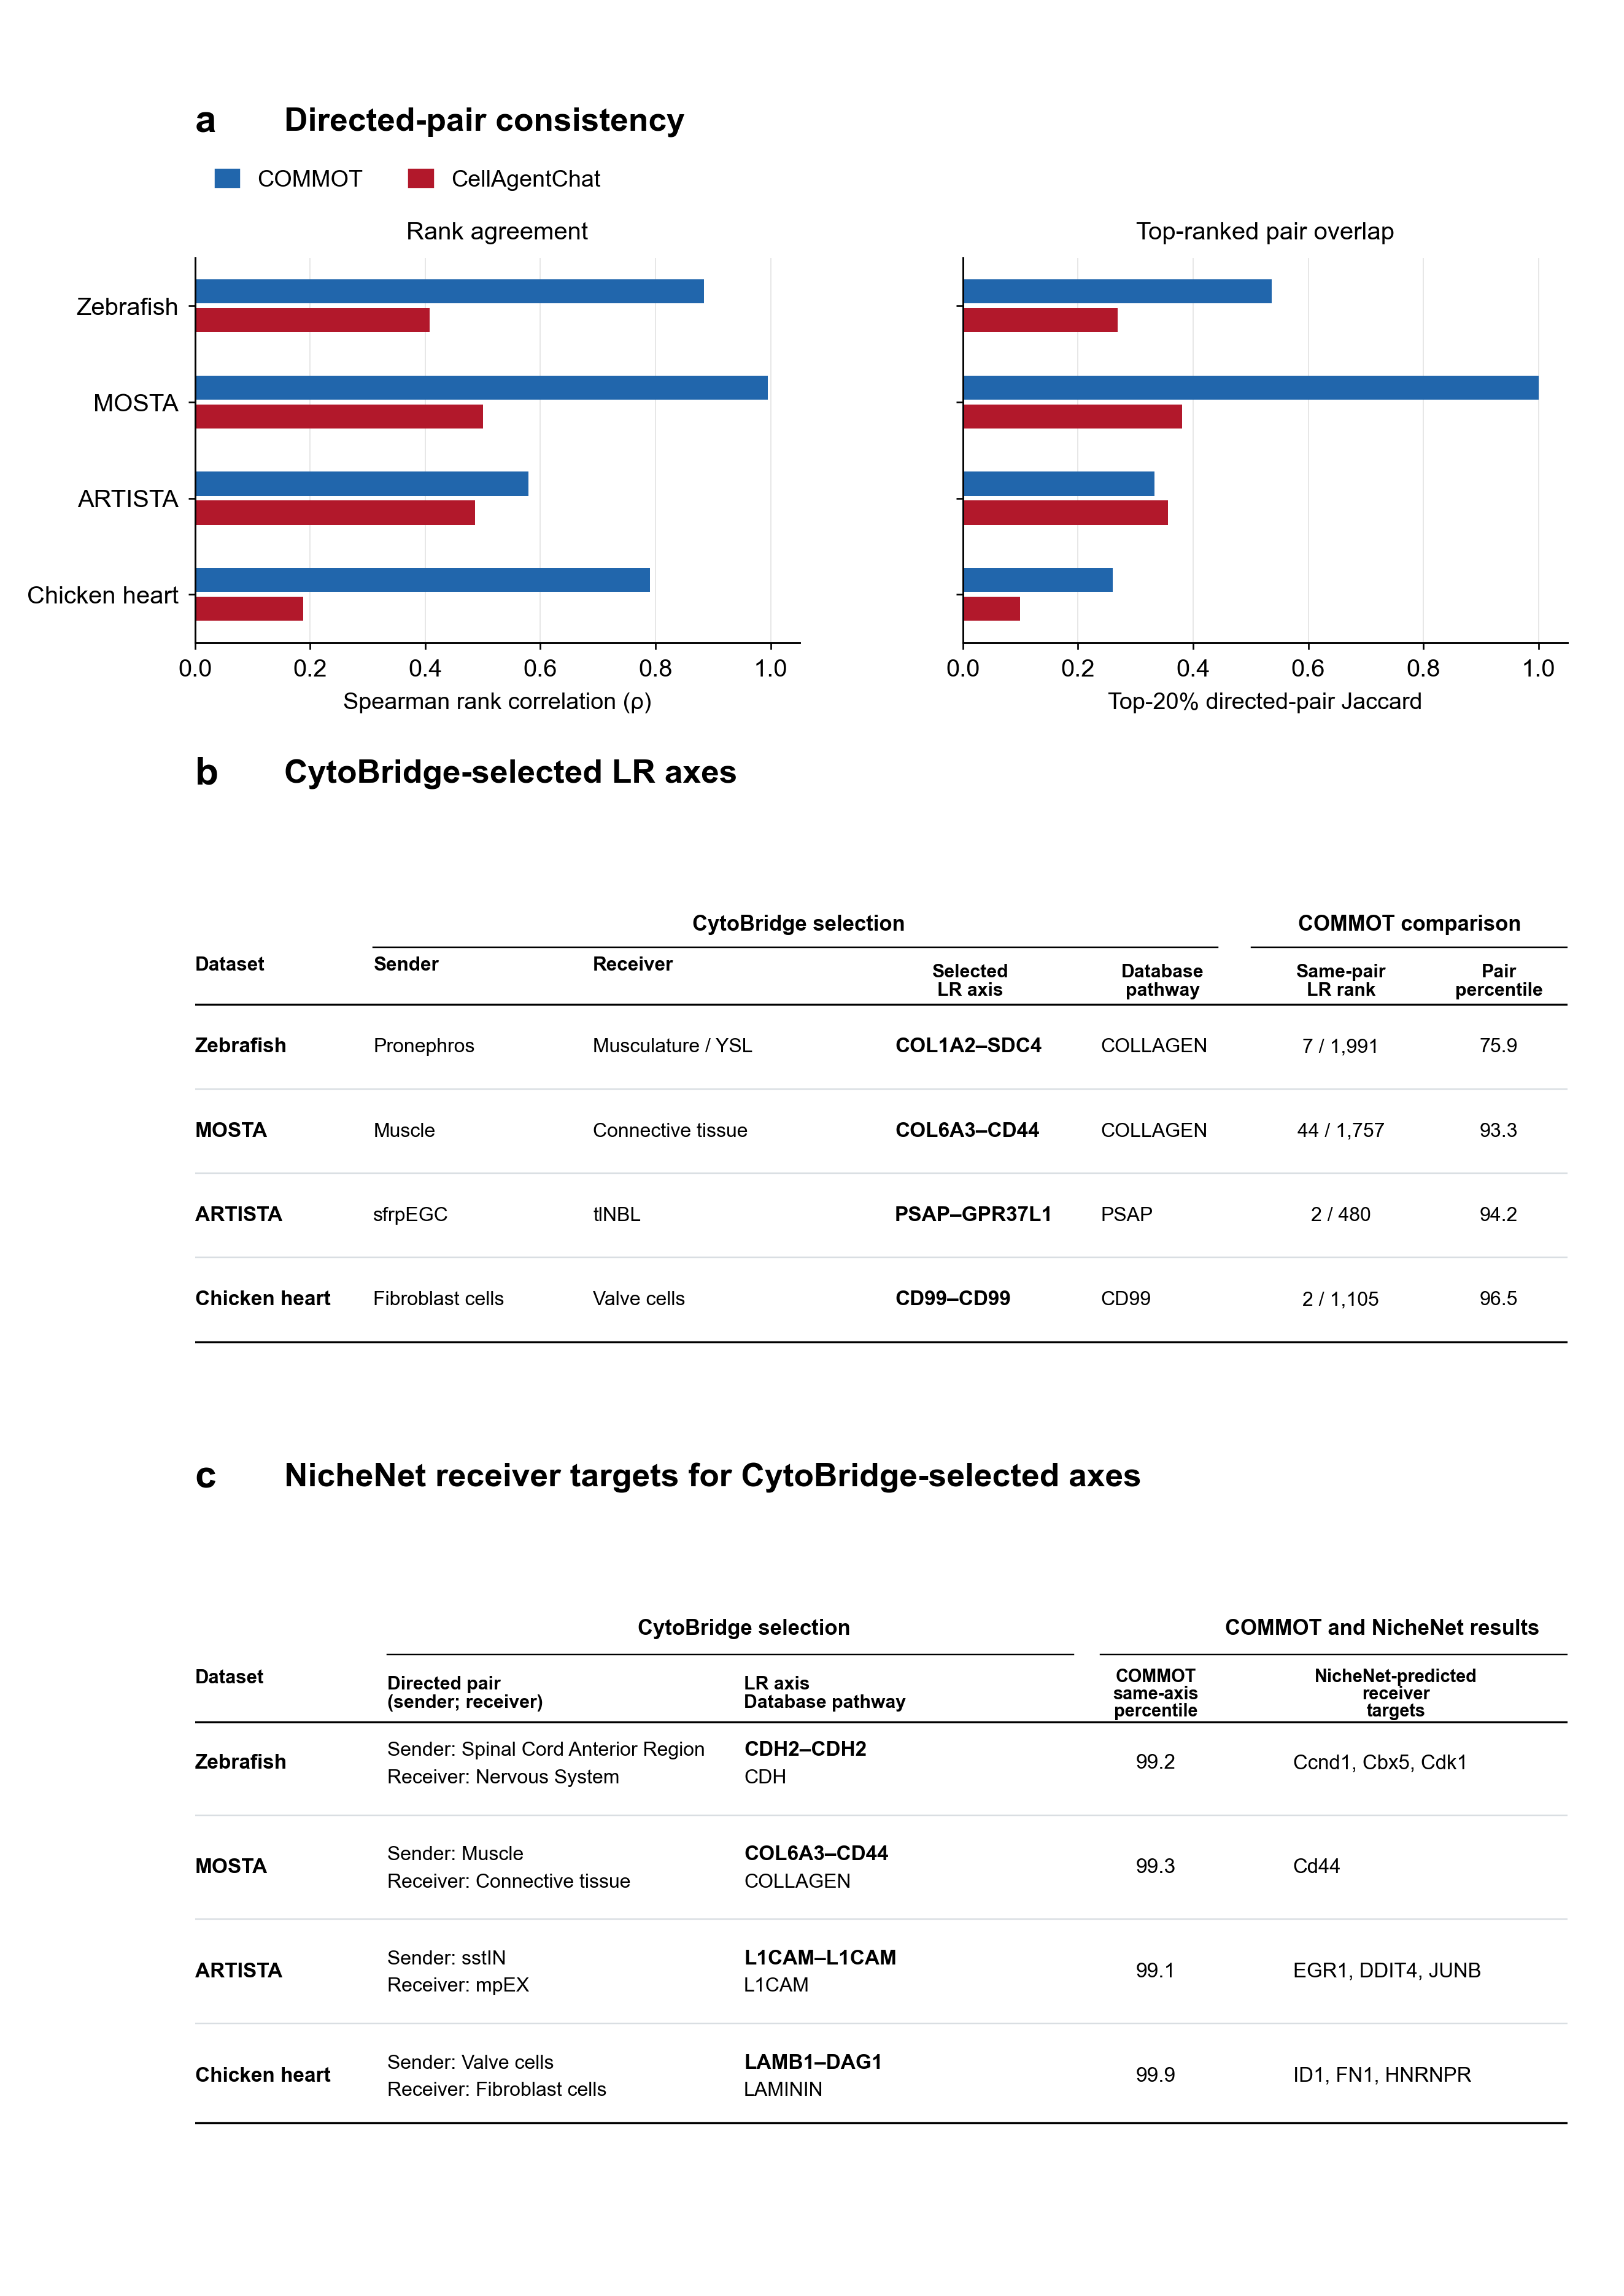

In [3]:
pdf, png = draw_supplementary([11], output, results_dir=data)["s11"]
display(Image(filename=str(png), width=850))